<a href="https://colab.research.google.com/github/mariamhamdi917-stack/ML_projects/blob/main/diabetesss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler



In [ ]:
df = pd.read_csv("/content/diabetes_patients_10000_full.csv")

In [ ]:
print(df.head())

   Patient_ID   Age  Gender  Blood_Sugar_Level  Creatinine   BMI  Urea  \
0           1  60.0    Male               96.0        1.34  22.5  23.0   
1           2  77.0    Male              241.0        1.02  19.0  28.0   
2           3  21.0    Male              229.0        1.02  25.9  32.0   
3           4  30.0  Female              177.0        0.88  22.1  36.0   
4           5  26.0  Female              178.0        1.20  31.8  44.0   

   Cholesterol  HbA1c     Class  
0        176.0    8.6  Diabetic  
1        209.0    7.5  Diabetic  
2        151.0    9.1  Diabetic  
3        176.0    5.1  Diabetic  
4        287.0    5.2  Diabetic  


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   object 
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 781.4+ KB
None


In [ ]:
print(df.isnull().sum())

Patient_ID            0
Age                  14
Gender               40
Blood_Sugar_Level    53
Creatinine           56
BMI                  51
Urea                 51
Cholesterol          32
HbA1c                 0
Class                 0
dtype: int64


In [ ]:
print(df.duplicated().sum())

0


In [ ]:
df = df.dropna()

In [ ]:
print(df.isnull().sum())

Patient_ID           0
Age                  0
Gender               0
Blood_Sugar_Level    0
Creatinine           0
BMI                  0
Urea                 0
Cholesterol          0
HbA1c                0
Class                0
dtype: int64


In [ ]:
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})
df['Class'] = df['Class'].map({'Non-Diabetic': 0, 'Diabetic': 1})

Text(0.5, 1.0, 'Blood Sugar Distribution')

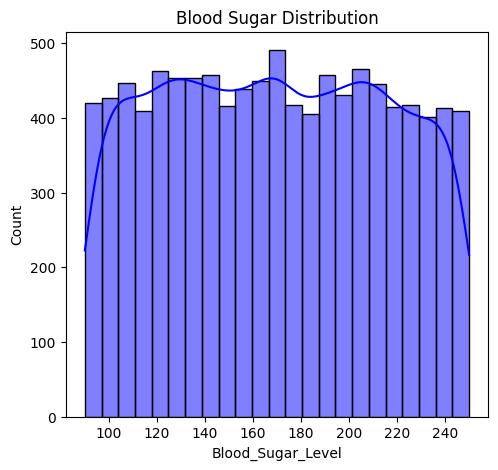

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['Blood_Sugar_Level'], kde=True, color='blue')
plt.title('Blood Sugar Distribution')



/tmp/ipykernel_1300/2390623022.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df, palette='Set2')


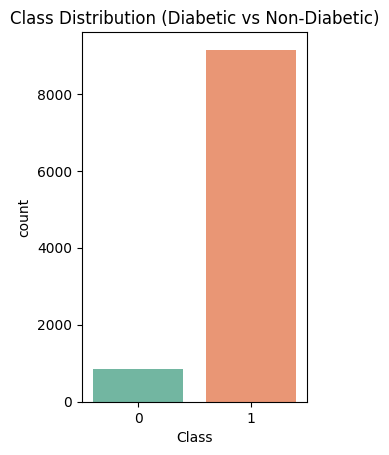

In [ ]:
plt.subplot(1, 2, 2)
sns.countplot(x='Class', data=df, palette='Set2')
plt.title('Class Distribution (Diabetic vs Non-Diabetic)')
plt.show()

In [ ]:
X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

log_model = LogisticRegression(class_weight='balanced', random_state=42)
log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))

Accuracy: 0.9345

Classification Report:
               precision    recall  f1-score   support

           0       0.57      0.98      0.72       171
           1       1.00      0.93      0.96      1829

    accuracy                           0.93      2000
   macro avg       0.78      0.96      0.84      2000
weighted avg       0.96      0.93      0.94      2000



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_log))
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))

Confusion Matrix:
 [[ 168    3]
 [ 128 1701]]

Classification Report:
               precision    recall  f1-score   support

           0       0.57      0.98      0.72       171
           1       1.00      0.93      0.96      1829

    accuracy                           0.93      2000
   macro avg       0.78      0.96      0.84      2000
weighted avg       0.96      0.93      0.94      2000



In [ ]:
#KNN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

knn_model = KNeighborsClassifier()
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn))

Accuracy: 0.9525

Confusion Matrix:
 [[ 105   66]
 [  29 1800]]

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.61      0.69       171
           1       0.96      0.98      0.97      1829

    accuracy                           0.95      2000
   macro avg       0.87      0.80      0.83      2000
weighted avg       0.95      0.95      0.95      2000



In [ ]:
#NAIVE BAIS
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))

Accuracy: 0.9865

Confusion Matrix:
 [[ 144   27]
 [   0 1829]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.84      0.91       171
           1       0.99      1.00      0.99      1829

    accuracy                           0.99      2000
   macro avg       0.99      0.92      0.95      2000
weighted avg       0.99      0.99      0.99      2000



In [ ]:
#SVM
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

svm_model = SVC(random_state=42)
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))

Accuracy: 0.976

Confusion Matrix:
 [[ 135   36]
 [  12 1817]]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.79      0.85       171
           1       0.98      0.99      0.99      1829

    accuracy                           0.98      2000
   macro avg       0.95      0.89      0.92      2000
weighted avg       0.98      0.98      0.98      2000



In [ ]:
#Decission Tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))

Accuracy: 0.9995

Confusion Matrix:
 [[ 170    1]
 [   0 1829]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      1.00       171
           1       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



             Feature  Importance
3  Blood_Sugar_Level    0.729319
8              HbA1c    0.268280
1                Age    0.002401
0         Patient_ID    0.000000
2             Gender    0.000000
4         Creatinine    0.000000
5                BMI    0.000000
6               Urea    0.000000
7        Cholesterol    0.000000


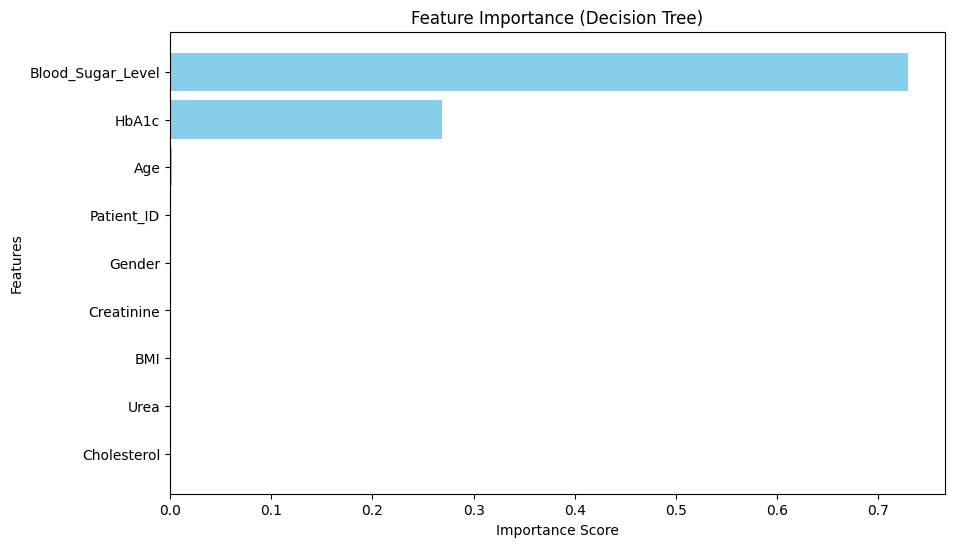

In [ ]:
importance = dt_model.feature_importances_
feature_importance_df = pd.DataFrame({'Feature': X.columns, 'Importance': importance})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

print(feature_importance_df)

plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='skyblue')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance (Decision Tree)')
plt.gca().invert_yaxis()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)

Best Parameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}
Best Score: 0.99975
